# Toy Experiments

We want to perform ASR with Continuous Flow Matching. This is, predicting a sequence of categorical tokens by cross-attending to a continuous latent embedding that contains information about the whole sequence.

To do this, we want to consider the following toy experiment. Let's create a vocabulary of $|\mathcal{V}|$ tokens and try to predict sequences of L tokens.

Let's say valid sequences are the ones in which the $\sum_\ell w^\ell = 0$.

We want to condition on $a^\ell = e_{w^\ell} + \eta \, \varepsilon^\ell, \varepsilon \sim \mathcal{N}(0, I)$ with $\eta$ controlling the noise level.

In [12]:
import math
from dataclasses import dataclass, field
from typing import Optional, Callable
from functools import partial

import torch
import torch.nn as nn
import torch.nn.functional as F

import matplotlib.pyplot as plt

if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")


### Define HPs

In [2]:
VOCAB_SIZE = 15
SEQ_LENGTH = 8
NUM_SAMPLES = 10000
NUM_VALID_TRANSITIONS = 4
REQUIRE_EVEN_SUM = True

### Create Dataset

In [3]:
def create_transition_matrix(vocab_size, num_valid_transitions, device):
    # row indices: each row repeated k times -> shape (V, k)
    row_idx = torch.arange(vocab_size, device=device).unsqueeze(1).expand(-1, num_valid_transitions)

    # distinct successors per row, sampled without replacement
    col_idx = torch.stack([
        torch.randperm(vocab_size)[:num_valid_transitions]
        for _ in range(vocab_size)
    ])

    transition_matrix = torch.zeros((vocab_size, vocab_size), dtype=torch.int32, device=device)
    transition_matrix[row_idx, col_idx] = 1

    # each row has exactly k successors
    assert (transition_matrix.sum(dim=1) == num_valid_transitions).all()

    return transition_matrix

def count_valid(trans_matrix, seq_length):
    ones = torch.ones(trans_matrix.shape[0], device=trans_matrix.device)
    M = torch.linalg.matrix_power(trans_matrix, seq_length - 1)
    return int((ones @ M @ ones).item())


def sample_sequence(
    trans_matrix,
    sample_size,
    seq_length,
    device=None,
    require_even_sum=True
):
    device = device or trans_matrix.device
    vocab_size = trans_matrix.shape[0]

    # Uniform distribution
    first_token_dist = torch.ones(vocab_size, device=device) / vocab_size

    # Sample first token
    w = torch.zeros(sample_size, seq_length, dtype=torch.long, device=device)
    w[:, 0] = torch.multinomial(first_token_dist, sample_size, replacement=True)

    # Fill the rest of the sequence
    for l in range(1, seq_length):
        probs = trans_matrix[w[:, l - 1]]
        w[:, l] = torch.multinomial(probs, 1).squeeze(1)

    if require_even_sum:
        even_sum_mask = (w.sum(dim=1) % 2 == 0)
        w = w[even_sum_mask]

    return w


In [7]:
transition_matrix = create_transition_matrix(VOCAB_SIZE, NUM_VALID_TRANSITIONS, device=device)
valid_seq_count = count_valid(transition_matrix.float(), seq_length=SEQ_LENGTH)

print(
    f"Valid sequences of length {SEQ_LENGTH}: {valid_seq_count}"
)

# row-normalize for sampling
prob_trans_matrix = transition_matrix.float() / transition_matrix.sum(dim=1, keepdim=True)

all_sequences = torch.empty(0, SEQ_LENGTH, dtype=torch.long, device=device)

if REQUIRE_EVEN_SUM:
    print("Sampling only sequences with even sum.")
    valid_seq_count = int(valid_seq_count * 0.49)  # Adjust this as needed

while all_sequences.shape[0] < valid_seq_count:
    new_samples = sample_sequence(
        prob_trans_matrix, NUM_SAMPLES, SEQ_LENGTH, device=device, require_even_sum=REQUIRE_EVEN_SUM
    )
    all_sequences = torch.cat([all_sequences, new_samples], dim=0)
    all_sequences = torch.unique(all_sequences, dim=0)

print(f"Sampled {all_sequences.shape[0]} unique sequences of length {SEQ_LENGTH} out of {valid_seq_count}.")


Valid sequences of length 8: 245760
Sampling only sequences with even sum.
Sampled 120478 unique sequences of length 8 out of 120422.


### Visualize how corruption messes w predictions

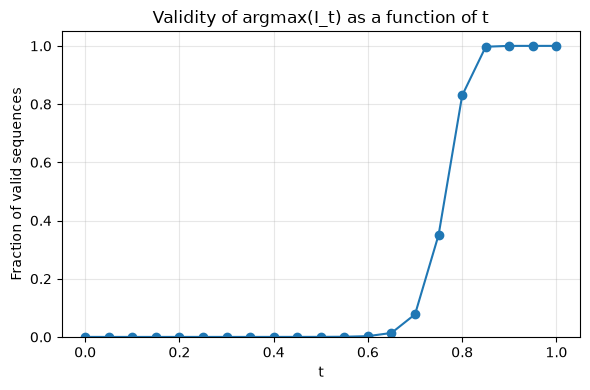

In [8]:
def check_valid(sequences, transition_matrix, require_even_sum=True):
    # Cut first and last tokens to get pairs of transitions
    prev = sequences[:, :-1]
    nxt  = sequences[:, 1:]

    # entry [b, l] = 1 iff (prev[b,l] -> nxt[b,l]) is a legal transition
    legal = transition_matrix[prev, nxt].bool()

    per_sequence_valid = legal.all(dim=1)   # (B,) — every transition must hold

    if require_even_sum:
        parity_valid = (sequences.sum(dim=1) % 2 == 0)
        per_sequence_valid = per_sequence_valid & parity_valid

    num_valid = per_sequence_valid.sum().item()
    frac_valid = per_sequence_valid.float().mean().item()

    return num_valid, frac_valid, per_sequence_valid


def linear_interpolant_simulation(sequences, vocab_size, t):
    onehot = F.one_hot(sequences, num_classes=vocab_size).float()
    noisy = t * onehot + (1 - t) * torch.randn_like(onehot)
    return noisy.argmax(dim=-1)

t_values = torch.linspace(0.0, 1.0, 21)
frac_valid_list = []

for t in t_values:
    noisy_samples = linear_interpolant_simulation(
        all_sequences, vocab_size=transition_matrix.shape[0], t=t.item()
    )
    _, frac_valid, _ = check_valid(noisy_samples, transition_matrix, require_even_sum=REQUIRE_EVEN_SUM)
    frac_valid_list.append(frac_valid)

plt.figure(figsize=(6, 4))
plt.plot(t_values.numpy(), frac_valid_list, marker="o")
plt.xlabel("t")
plt.ylabel("Fraction of valid sequences")
plt.title("Validity of argmax(I_t) as a function of t")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Design Audio Proxy

In [44]:
def make_phi(
    vocab_size,
    embed_dim,
    num_confusable_pairs=1,
    confusion_noise=0.1,
    device=None,
    generator=None
):
    assert 2 * num_confusable_pairs <= vocab_size, (
        f"Can't form {num_confusable_pairs} disjoint"
        f"pairs from a vocab of size {vocab_size}"
    )

    Phi = torch.randn(
        vocab_size, embed_dim, device=device, generator=generator
    )

    # sample num_confusable_pairs disjoint pairs from V tokens
    perm = torch.randperm(
        vocab_size, generator=generator
    )[: 2 * num_confusable_pairs]
    pairs = perm.view(num_confusable_pairs, 2)  # (num_pairs, 2), each row a disjoint pair

    for i, j in pairs:
        Phi[j] = Phi[i] + confusion_noise * torch.randn(embed_dim, device=device, generator=generator)

    return Phi, pairs

def make_audio_proxy(w, Phi, kernel, eta, audio_dim):
    emb = Phi[w] # (B, L, d)
    emb_t = emb.transpose(1, 2) # (B, d, L)
    smoothed = F.conv1d(
        emb_t,
        kernel.expand(audio_dim, 1, -1),
        padding=kernel.shape[-1]//2,
        groups=audio_dim
    )
    smoothed = smoothed.transpose(1, 2) # (B, L, d)
    return smoothed + eta * torch.randn_like(smoothed, device=smoothed.device)


### Viz Audio Embeddings

In [45]:
def plot_phi_confusability(Phi, pairs, vocab_size):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

    # (a) pairwise distance matrix
    dists = torch.cdist(Phi, Phi)
    im = axes[0].imshow(dists.cpu(), cmap="viridis")
    axes[0].set_title("Pairwise distance in Φ-space")
    axes[0].set_xlabel("token")
    axes[0].set_ylabel("token")
    fig.colorbar(im, ax=axes[0], fraction=0.046)

    for i, j in pairs:
        axes[0].scatter([j.item()], [i.item()], marker="x", color="red", s=60)
        axes[0].scatter([i.item()], [j.item()], marker="x", color="red", s=60)

    # (b) 2D projection (PCA) of Phi, only confusable-pair tokens labelled
    Phi_c = Phi - Phi.mean(dim=0, keepdim=True)
    U, S, V = torch.pca_lowrank(Phi_c, q=2)
    proj = Phi_c @ V[:, :2]

    axes[1].scatter(proj[:, 0].cpu(), proj[:, 1].cpu(), s=80, color="tab:blue")

    confusable_tokens = pairs.reshape(-1)  # flatten (num_pairs, 2) -> all involved token indices
    for v in confusable_tokens:
        v = v.item()
        axes[1].annotate(str(v), (proj[v, 0].item(), proj[v, 1].item()), fontsize=12, fontweight="bold",
                          xytext=(4, 4), textcoords="offset points")

    for i, j in pairs:
        axes[1].plot([proj[i, 0].item(), proj[j, 0].item()],
                      [proj[i, 1].item(), proj[j, 1].item()], "r--", alpha=0.7)
    axes[1].set_title("Φ projected to 2D (PCA), confusable pairs linked")

    fig.tight_layout()
    plt.show()


def plot_audio_proxy_confusion(Phi, kernel, audio_dim, w, eta_values):
    """For one fixed batch of ground-truth sequences w, sweep eta and measure
    how often nearest-neighbour decoding of the audio proxy recovers the
    original token, split into 'involves a confusable token' vs not."""

    frac_correct = []

    for eta in eta_values:
        a = make_audio_proxy(w, Phi, kernel, eta, audio_dim)   # (B, L, d)
        # nearest-neighbour decode: which token's Phi row is closest to each a^l
        dists = torch.cdist(a.reshape(-1, audio_dim), Phi)      # (B*L, V)
        pred = dists.argmin(dim=1).reshape(w.shape)              # (B, L)

        correct = (pred == w)
        frac_correct.append(correct.float().mean().item())

    plt.figure(figsize=(6, 4))
    plt.plot(eta_values, frac_correct, marker="o")
    plt.xlabel("eta (noise scale)")
    plt.ylabel("Nearest-neighbour decode accuracy")
    plt.title("Audio proxy informativeness vs eta")
    plt.ylim(0, 1.05)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

### Define Models

In [9]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):  # t: (B,)
        half = self.dim // 2
        freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
        args = t[:, None] * freqs[None, :]  # (B, half)
        return torch.cat([torch.sin(args), torch.cos(args)], dim=-1)  # (B, dim)


class DenoiserBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff):
        super().__init__()
        self.attn = nn.MultiheadAttention(d_model, n_heads, batch_first=True)
        self.norm1 = nn.LayerNorm(d_model)
        self.ff = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Linear(d_ff, d_model)
        )
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, x):
        # bidirectional self-attention — no causal mask, the model sees all positions
        h = self.norm1(x)
        x = x + self.attn(h, h, h, need_weights=False)[0]
        x = x + self.ff(self.norm2(x))
        return x

class Denoiser(nn.Module):
    def __init__(self, vocab_size, seq_len, audio_dim=None, d_model=128, n_heads=4, n_layers=3, d_ff=256):
        super().__init__()
        audio_dim = audio_dim if audio_dim is not None else vocab_size  # default: plain one-hot proxy
        self.x_proj = nn.Linear(vocab_size, d_model)
        self.a_proj = nn.Linear(audio_dim, d_model)
        self.time_embed = SinusoidalTimeEmbedding(d_model)
        self.pos_embed = nn.Parameter(torch.randn(1, seq_len, d_model) * 0.02)
        self.blocks = nn.ModuleList([DenoiserBlock(d_model, n_heads, d_ff) for _ in range(n_layers)])
        self.norm_out = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size)

    def forward(self, x_t, t, a):
        # x_t: (B, L, V), t: (B,), a: (B, L, audio_dim)
        h = self.x_proj(x_t) + self.a_proj(a) + self.pos_embed
        h = h + self.time_embed(t)[:, None, :]
        for block in self.blocks:
            h = block(h)
        return self.head(self.norm_out(h))

class AudioDecoder(nn.Module):
    """r_psi: predicts per-token categorical distributions from audio alone.
    Strictly factorized across positions — no attention, no dependence on x_t or t.
    """
    def __init__(self, audio_dim, vocab_size, hidden_dim=128, n_layers=2):
        super().__init__()
        layers = []
        in_dim = audio_dim
        for _ in range(n_layers - 1):
            layers += [nn.Linear(in_dim, hidden_dim), nn.GELU()]
            in_dim = hidden_dim
        layers.append(nn.Linear(in_dim, vocab_size))
        self.net = nn.Sequential(*layers)

    def forward(self, a):
        return self.net(a)

### Define Interpolation Function

In [55]:
def make_interpolant(x1, t, alpha_fn, beta_fn, gamma_fn=None, mu=None, stop_grad_mu=False, device=None):
    device = device if device is not None else x1.device
    x0 = torch.randn_like(x1, device=device)
    I_t = alpha_fn(t)[:, None, None] * x0 + beta_fn(t)[:, None, None] * x1
    if gamma_fn is not None and mu is not None:
        mu_term = mu.detach() if stop_grad_mu else mu
        I_t = I_t + gamma_fn(t)[:, None, None] * mu_term
    return I_t

### Define Training Loop

In [51]:
def make_epoch_loader(sequences, batch_size, shuffle):
    return torch.utils.data.DataLoader(sequences, batch_size=batch_size, shuffle=shuffle)

def run_epoch(
    model,
    loader,
    transition_matrix,
    device,
    interpolant_fn,
    optimizer=None,
    scheduler=None,
    audio_sigma=0.5,
    audio_proxy_fn=None,
    require_even_sum=True,
    mu_nn=None,
    mu_loss_weight=1.0,
):
    """One pass over `loader`. If optimizer is given, trains; otherwise evaluates.
    Returns a dict of epoch-averaged metrics."""
    train_mode = optimizer is not None
    model.train() if train_mode else model.eval()

    total_loss, total_seqs = 0.0, 0
    total_valid, total_unique_valid = 0, 0

    ctx = torch.enable_grad() if train_mode else torch.no_grad()
    with ctx:
        for batch in loader:
            batch = batch.to(device)
            B = batch.size(0)
            vocab_size = model.head.out_features

            x1 = F.one_hot(batch, vocab_size).float()

            if audio_proxy_fn is not None:
                a = audio_proxy_fn(batch)
            else:
                a = x1 + audio_sigma * torch.randn_like(x1)

            if mu_nn is not None:
                mu = mu_nn(a)
            else:
                mu = None

            t = torch.rand(B, device=device)
            I_t = interpolant_fn(x1=x1, t=t, mu=mu, device=device)

            logits = model(I_t, t, a)
            loss = F.cross_entropy(logits.reshape(-1, vocab_size), batch.reshape(-1))

            if mu_nn is not None:
                mu_loss = F.cross_entropy(mu.reshape(-1, vocab_size), batch.reshape(-1))
                loss += mu_loss_weight * mu_loss

            if train_mode:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
                if scheduler is not None:
                    scheduler.step()

            pred_sequences = logits.argmax(dim=-1)
            num_valid, _, valid_mask = check_valid(pred_sequences, transition_matrix, require_even_sum=require_even_sum)
            num_unique_valid = torch.unique(pred_sequences[valid_mask], dim=0).size(0) if num_valid > 0 else 0

            total_loss += loss.item() * B
            total_seqs += B
            total_valid += num_valid
            total_unique_valid += num_unique_valid

    return {
        "loss": total_loss / total_seqs,
        "frac_valid": total_valid / total_seqs,
        "unique_valid_count": total_unique_valid,   # not a fraction across batches — see note below
    }


@dataclass
class TrainConfig:
    num_epochs: int = 1000
    audio_sigma: float = 0.5
    require_even_sum: bool = True
    mu_loss_weight: float = 1.0
    log_every: int = 1
    audio_proxy_fn: Optional[Callable] = None
    interpolant_fn: Callable = None  # required — no sensible default

    def __post_init__(self):
        if self.interpolant_fn is None:
            raise ValueError("interpolant_fn must be provided")


def train(
    model,
    loader_train,
    loader_val,
    transition_matrix,
    device,
    optimizer,
    scheduler,
    config: TrainConfig,
    mu_nn=None,
):
    history = {"train": [], "val": []}

    for epoch in range(config.num_epochs):
        train_metrics = run_epoch(
            model,
            loader_train,
            transition_matrix,
            device,
            interpolant_fn=config.interpolant_fn,
            optimizer=optimizer,
            scheduler=scheduler,
            audio_sigma=config.audio_sigma,
            audio_proxy_fn=config.audio_proxy_fn,
            require_even_sum=config.require_even_sum,
            mu_nn=mu_nn,
            mu_loss_weight=config.mu_loss_weight,
        )
        val_metrics = run_epoch(
            model,
            loader_val,
            transition_matrix,
            device,
            interpolant_fn=config.interpolant_fn,
            optimizer=None,
            scheduler=None,
            audio_sigma=config.audio_sigma,
            audio_proxy_fn=config.audio_proxy_fn,
            require_even_sum=config.require_even_sum,
            mu_nn=mu_nn,
            mu_loss_weight=config.mu_loss_weight,
        )

        history["train"].append(train_metrics)
        history["val"].append(val_metrics)

        if epoch % config.log_every == 0:
            print(
                f"Epoch {epoch+1}/{config.num_epochs} | "
                f"train loss {train_metrics['loss']:.4f} valid% {train_metrics['frac_valid']*100:.1f} | "
                f"val loss {val_metrics['loss']:.4f} valid% {val_metrics['frac_valid']*100:.1f}"
            )

    return history

### Shuffle and Split Datasets

In [16]:
BS = 2048

perm = torch.randperm(all_sequences.size(0))
all_sequences = all_sequences[perm]

train_size = int(0.8 * all_sequences.size(0))
train_data = all_sequences[:train_size]
val_data = all_sequences[train_size:]

train_loader = make_epoch_loader(train_data, BS, shuffle=True)
val_loader = make_epoch_loader(val_data, BS, shuffle=False)


### Make Audio Proxy

confusable pairs: tensor([[13,  7],
        [12,  0]])


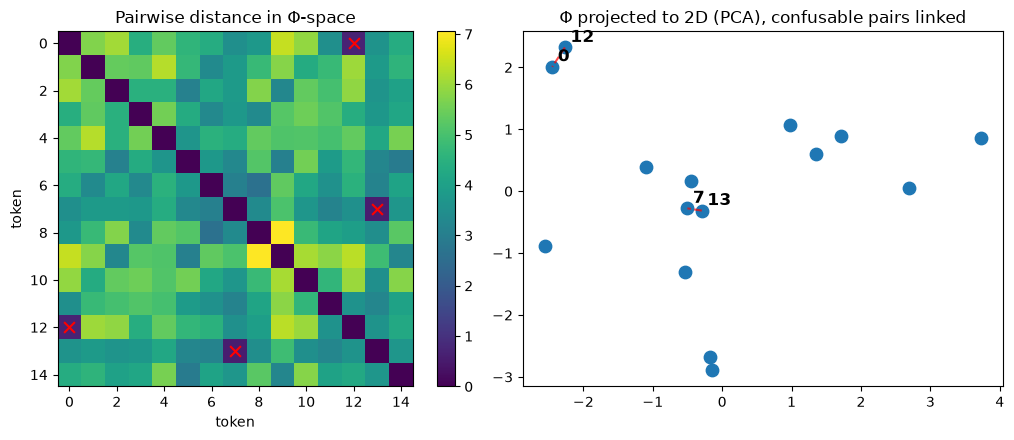

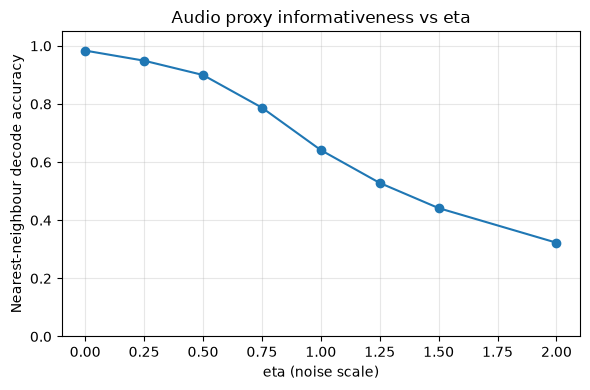

In [49]:
AUDIO_DIM = 10
CONFUSION_NOISE = 0.2
NUM_CONFUSABLE_PAIRS = 2
ETA = 1
KERNEL = torch.tensor([0.1, 0.8, 0.1], device=device).view(1, 1, 3)

Phi, confusable_pairs = make_phi(
    VOCAB_SIZE,
    AUDIO_DIM,
    num_confusable_pairs=NUM_CONFUSABLE_PAIRS,
    confusion_noise=CONFUSION_NOISE,
    device=device
)
print("confusable pairs:", confusable_pairs)
plot_phi_confusability(Phi, confusable_pairs, vocab_size=8)

audio_proxy_fn = partial(
    make_audio_proxy, Phi=Phi, kernel=KERNEL, eta=ETA, audio_dim=AUDIO_DIM
)

eta_values = [0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 2.0]
plot_audio_proxy_confusion(Phi, KERNEL, audio_dim=AUDIO_DIM, w=all_sequences[:2048], eta_values=eta_values)


### Train Regular Flow

In [52]:
NUM_EPOCHS = 50
AUDIO_SIGMA = 0.5
MAX_LR = 1e-2

# Define the Model
model = Denoiser(vocab_size=VOCAB_SIZE, seq_len=SEQ_LENGTH, audio_dim=AUDIO_DIM).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=MAX_LR)

steps_per_epoch = len(train_loader)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=MAX_LR,
    total_steps=steps_per_epoch * NUM_EPOCHS,
)

# Define Linear Interpolant Function
interpolant_fn = partial(
    make_interpolant,
    alpha_fn=lambda t: 1 - t,
    beta_fn=lambda t: t,
)

config = TrainConfig(
    num_epochs=NUM_EPOCHS,
    audio_sigma=AUDIO_SIGMA,
    require_even_sum=REQUIRE_EVEN_SUM,
    mu_loss_weight=None,
    audio_proxy_fn=audio_proxy_fn,
    interpolant_fn=interpolant_fn,
)

history = train(
    model=model,
    loader_train=train_loader,
    loader_val=val_loader,
    transition_matrix=transition_matrix,
    device=device,
    optimizer=optimizer,
    scheduler=scheduler,
    config=config,
    mu_nn=None,
)

Epoch 1/50 | train loss 1.3930 valid% 5.4 | val loss 0.8957 valid% 10.7
Epoch 2/50 | train loss 0.8148 valid% 14.1 | val loss 0.7689 valid% 17.3
Epoch 3/50 | train loss 0.7302 valid% 20.5 | val loss 0.6594 valid% 28.1
Epoch 4/50 | train loss 0.6014 valid% 32.8 | val loss 0.5756 valid% 34.9
Epoch 5/50 | train loss 0.5608 valid% 36.2 | val loss 0.5656 valid% 36.5
Epoch 6/50 | train loss 0.5517 valid% 37.0 | val loss 0.5587 valid% 36.5
Epoch 7/50 | train loss 0.5454 valid% 37.5 | val loss 0.5420 valid% 37.6
Epoch 8/50 | train loss 0.5078 valid% 40.3 | val loss 0.5234 valid% 40.0
Epoch 9/50 | train loss 0.3590 valid% 56.1 | val loss 0.3320 valid% 60.0
Epoch 10/50 | train loss 0.2902 valid% 65.3 | val loss 0.3592 valid% 60.4
Epoch 11/50 | train loss 0.2954 valid% 65.7 | val loss 0.2949 valid% 66.2
Epoch 12/50 | train loss 0.2619 valid% 69.8 | val loss 0.3289 valid% 64.1
Epoch 13/50 | train loss 0.2614 valid% 70.0 | val loss 0.2796 valid% 67.8
Epoch 14/50 | train loss 0.2557 valid% 70.6 | va

KeyboardInterrupt: 

### Train Audio-Conditioned Variant

In [56]:
NUM_EPOCHS = 50
AUDIO_SIGMA = 0.5
DENOISER_LR = 1e-2
AUDIO_DECODER_LR = 5e-2
STOP_GRAD_MU = True

# Define the Model
model = Denoiser(vocab_size=VOCAB_SIZE, seq_len=SEQ_LENGTH, audio_dim=AUDIO_DIM).to(device)
mu_nn = AudioDecoder(audio_dim=AUDIO_DIM, vocab_size=VOCAB_SIZE).to(device)
param_groups = [
    {"params": model.parameters(), "lr": DENOISER_LR},
    {"params": mu_nn.parameters(), "lr": AUDIO_DECODER_LR},
]
optimizer = torch.optim.AdamW(param_groups)

steps_per_epoch = len(train_loader)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=[DENOISER_LR, AUDIO_DECODER_LR],
    total_steps=steps_per_epoch * NUM_EPOCHS,
)

# Define Audio-Conditioned Linear Interpolant Function
interpolant_fn = partial(
    make_interpolant,
    alpha_fn=lambda t: 1 - t,
    beta_fn=lambda t: t,
    gamma_fn=lambda t: 1 - t,
    stop_grad_mu=STOP_GRAD_MU
)

config = TrainConfig(
    num_epochs=NUM_EPOCHS,
    audio_sigma=AUDIO_SIGMA,
    require_even_sum=REQUIRE_EVEN_SUM,
    mu_loss_weight=None,
    audio_proxy_fn=audio_proxy_fn,
    interpolant_fn=interpolant_fn,
)

history = train(
    model=model,
    loader_train=train_loader,
    loader_val=val_loader,
    transition_matrix=transition_matrix,
    device=device,
    optimizer=optimizer,
    scheduler=scheduler,
    config=config,
    mu_nn=None,
)

Epoch 1/50 | train loss 1.4490 valid% 5.0 | val loss 0.9099 valid% 10.6
Epoch 2/50 | train loss 0.8235 valid% 13.8 | val loss 0.7783 valid% 16.3
Epoch 3/50 | train loss 0.7361 valid% 19.6 | val loss 0.6681 valid% 26.5
Epoch 4/50 | train loss 0.6056 valid% 32.3 | val loss 0.5821 valid% 34.5
Epoch 5/50 | train loss 0.5608 valid% 36.1 | val loss 0.5534 valid% 36.7
Epoch 6/50 | train loss 0.5513 valid% 37.1 | val loss 0.5499 valid% 37.0
Epoch 7/50 | train loss 0.5434 valid% 37.4 | val loss 0.5607 valid% 36.7
Epoch 8/50 | train loss 0.5126 valid% 39.8 | val loss 0.4911 valid% 42.4
Epoch 9/50 | train loss 0.3576 valid% 56.1 | val loss 0.3456 valid% 59.6
Epoch 10/50 | train loss 0.2928 valid% 65.0 | val loss 0.3205 valid% 63.9
Epoch 11/50 | train loss 0.2733 valid% 68.1 | val loss 0.3170 valid% 63.9


KeyboardInterrupt: 

### Train Three-Term Waypoint Variant

In [ ]:
NUM_EPOCHS = 50
AUDIO_SIGMA = 0.5
DENOISER_LR = 1e-2
AUDIO_DECODER_LR = 5e-2
# Make it peak at 0.5
C = 0.5

# Define the Model
model = Denoiser(vocab_size=VOCAB_SIZE, seq_len=SEQ_LENGTH, audio_dim=AUDIO_DIM).to(device)
mu_nn = AudioDecoder(audio_dim=AUDIO_DIM, vocab_size=VOCAB_SIZE).to(device)
param_groups = [
    {"params": model.parameters(), "lr": DENOISER_LR},
    {"params": mu_nn.parameters(), "lr": AUDIO_DECODER_LR},
]
optimizer = torch.optim.AdamW(param_groups)

steps_per_epoch = len(train_loader)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=[DENOISER_LR, AUDIO_DECODER_LR],
    total_steps=steps_per_epoch * NUM_EPOCHS,
)

# Define Three-term Waypoint Interpolant Function
interpolant_fn = partial(
    make_interpolant,
    alpha_fn=lambda t: 1 - t,
    beta_fn=lambda t: t,
    gamma_fn=lambda t: 4 * C * t * (1 - t),
)

config = TrainConfig(
    num_epochs=NUM_EPOCHS,
    audio_sigma=AUDIO_SIGMA,
    require_even_sum=REQUIRE_EVEN_SUM,
    mu_loss_weight=None,
    audio_proxy_fn=audio_proxy_fn,
    interpolant_fn=interpolant_fn,
)

history = train(
    model=model,
    loader_train=train_loader,
    loader_val=val_loader,
    transition_matrix=transition_matrix,
    device=device,
    optimizer=optimizer,
    scheduler=scheduler,
    config=config,
    mu_nn=None,
)